# Gated Recurrent Unit (GRU)

In [38]:
import os
import time
import json
import random
import itertools
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Reshape
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Data Preprocessing

In [39]:
df = pd.read_csv("day.csv")

df = df.rename(columns={"dteday": "date"})
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (731, 15)


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
date,,,,,,,,,,,,,,,
2011-01-01,1,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2011-01-02,2,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2011-01-03,3,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
2011-01-04,4,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
2011-01-05,5,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Feature Selection and Log Transformation

In [40]:
features = [
    "cnt",
    "casual",
    "registered",
    "temp",
    "atemp",
    "windspeed",
    "hum"
]

log_features = ["cnt", "casual", "registered"]

data = df[features].copy()

for col in log_features:
    data[col] = np.log(data[col])

print(data.head())

                 cnt    casual  registered      temp     atemp  windspeed  \
date                                                                        
2011-01-01  6.892642  5.802118    6.483107  0.344167  0.363625   0.160446   
2011-01-02  6.685861  4.875197    6.507278  0.363478  0.353739   0.248539   
2011-01-03  7.207119  4.787492    7.113956  0.196364  0.189405   0.248309   
2011-01-04  7.353722  4.682131    7.282074  0.200000  0.212122   0.160296   
2011-01-05  7.377759  4.406719    7.325149  0.226957  0.229270   0.186900   

                 hum  
date                  
2011-01-01  0.805833  
2011-01-02  0.696087  
2011-01-03  0.437273  
2011-01-04  0.590435  
2011-01-05  0.436957  


### Data Normalization

In [41]:
train_limit = int(len(data) * 0.70)

scalers = {}
scaled_columns = []

for col in features:

    scaler = MinMaxScaler()

    scaler.fit(data[[col]].iloc[:train_limit])

    scaled = scaler.transform(data[[col]])

    scalers[col] = scaler
    scaled_columns.append(scaled.flatten())

multivariate_data = np.column_stack(scaled_columns)

print("Scaled data shape:", multivariate_data.shape)

Scaled data shape: (731, 7)


### Sliding Window Sequences

In [42]:
def split_multivariate_sequences(sequences, lookback, horizon=1):

    X, y = [], []

    for i in range(len(sequences)):

        end_ix = i + lookback
        out_end_ix = end_ix + horizon

        if out_end_ix > len(sequences):
            break

        seq_x = sequences[i:end_ix, :]
        seq_y = sequences[end_ix:out_end_ix, :]

        X.append(seq_x)
        y.append(seq_y)

    return np.array(X), np.array(y)


L = 7
h = 1

X, y = split_multivariate_sequences(
    multivariate_data,
    lookback=L,
    horizon=h
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (724, 7, 7)
y shape: (724, 1, 7)


### Train, Validation, and Test Split

In [43]:
total_samples = len(X)

train_end = int(total_samples * 0.70)
val_end = int(total_samples * 0.85)

X_train = X[:train_end]
X_val = X[train_end:val_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

n_steps = X_train.shape[1]
n_features = X_train.shape[2]
horizon = y_train.shape[1]
output_dim = y_train.shape[2]

Training: (506, 7, 7) (506, 1, 7)
Validation: (109, 7, 7) (109, 1, 7)
Testing: (109, 7, 7) (109, 1, 7)


## GRU Model

In [44]:
def build_gru_model(units=64, dropout=0.0, learning_rate=0.001):

    model = Sequential([
        Input(shape=(n_steps, n_features)),

        GRU(
            units=units,
            activation="tanh",
            dropout=dropout
        ),

        Dense(horizon * output_dim),

        Reshape((horizon, output_dim))
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"]
    )

    return model


gru_model = build_gru_model()

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                          │ (None, 64)                  │          14,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             455 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_1 (Reshape)                  │ (None, 1, 7)                │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,471 (56.53 KB)

 Trainable params: 14,471 (56.53 KB)

 Non-trainable params: 0 (0.00 B)

## Hyperparameter Tuning

In [45]:
search_space = {
    "units": [32, 64],
    "dropout": [0.0, 0.2],
    "learning_rate": [0.001, 0.0001],
    "batch_size": [16, 32]
}

MAX_EPOCHS = 50
PATIENCE = 8

combinations = list(itertools.product(
    search_space["units"],
    search_space["dropout"],
    search_space["learning_rate"],
    search_space["batch_size"]
))

print("Total trials:", len(combinations))

Total trials: 16


### Grid Search

In [46]:
results = []
best_val_loss = float("inf")
best_config = None

os.makedirs("gru_checkpoints", exist_ok=True)

for trial, (units, dropout, lr, batch_size) in enumerate(
    combinations, start=1
):

    print(f"Trial {trial}/{len(combinations)}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_gru_model(
        units=units,
        dropout=dropout,
        learning_rate=lr
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0,
        shuffle=False
    )

    training_time = time.perf_counter() - start_time

    val_mse, val_mae = model.evaluate(
        X_val, y_val, verbose=0
    )

    start_inference = time.perf_counter()
    model.predict(X_val, verbose=0)
    inference_time = time.perf_counter() - start_inference

    results.append({
        "trial": trial,
        "units": units,
        "dropout": dropout,
        "learning_rate": lr,
        "batch_size": batch_size,
        "val_mse": val_mse,
        "val_mae": val_mae,
        "parameters": model.count_params(),
        "epochs": len(history.history["loss"]),
        "training_time_s": training_time,
        "inference_time_s": inference_time
    })

    if val_mse < best_val_loss:

        best_val_loss = val_mse

        best_config = {
            "units": units,
            "dropout": dropout,
            "learning_rate": lr,
            "batch_size": batch_size
        }

        model.save("gru_checkpoints/best_gru.keras")

    print("Validation MSE:", val_mse)

print("Grid search completed!")

Trial 1/16
Validation MSE: 0.00786055438220501
Trial 2/16
Validation MSE: 0.006718516815453768
Trial 3/16
Validation MSE: 0.014361363835632801
Trial 4/16
Validation MSE: 0.021072445437312126
Trial 5/16
Validation MSE: 0.0130614023655653
Trial 6/16
Validation MSE: 0.012380175292491913
Trial 7/16
Validation MSE: 0.01619015820324421
Trial 8/16
Validation MSE: 0.020182933658361435
Trial 9/16
Validation MSE: 0.007310968358069658
Trial 10/16
Validation MSE: 0.006387077271938324
Trial 11/16
Validation MSE: 0.008055961690843105
Trial 12/16
Validation MSE: 0.012695565819740295
Trial 13/16
Validation MSE: 0.01263581495732069
Trial 14/16
Validation MSE: 0.011790533550083637
Trial 15/16
Validation MSE: 0.012736822478473186
Trial 16/16
Validation MSE: 0.01543109118938446
Grid search completed!


## Results of Best Model

In [47]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="val_mse"
).reset_index(drop=True)

display(results_df)

results_df.to_csv("gru_hpo_results.csv", index=False)

print("Best configuration:", best_config)
print("Best validation MSE:", best_val_loss)

,trial,units,dropout,learning_rate,batch_size,val_mse,val_mae,parameters,epochs,training_time_s,inference_time_s
0,10,64,0.0,0.0010,32,0.006387,0.058905,14471,50,8.953134,0.412067
1,2,32,0.0,0.0010,32,0.006719,0.062074,4167,50,8.372531,0.392638
2,9,64,0.0,0.0010,16,0.007311,0.063433,14471,50,10.049090,0.399096
3,1,32,0.0,0.0010,16,0.007861,0.067652,4167,26,6.246923,0.387961
4,11,64,0.0,0.0001,16,0.008056,0.068932,14471,50,9.480826,0.366054
5,14,64,0.2,0.0010,32,0.011791,0.088893,14471,17,4.248055,0.344952
6,6,32,0.2,0.0010,32,0.012380,0.091805,4167,35,6.586354,0.399576
7,13,64,0.2,0.0010,16,0.012636,0.088023,14471,17,4.732063,0.407628
8,12,64,0.0,0.0001,32,0.012696,0.092751,14471,50,8.710831,0.314062
9,15,64,0.2,0.0001,16,0.012737,0.093565,14471,50,9.642326,0.396805


Best configuration: {'units': 64, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32}
Best validation MSE: 0.006387077271938324


### Validation MSE Comparison

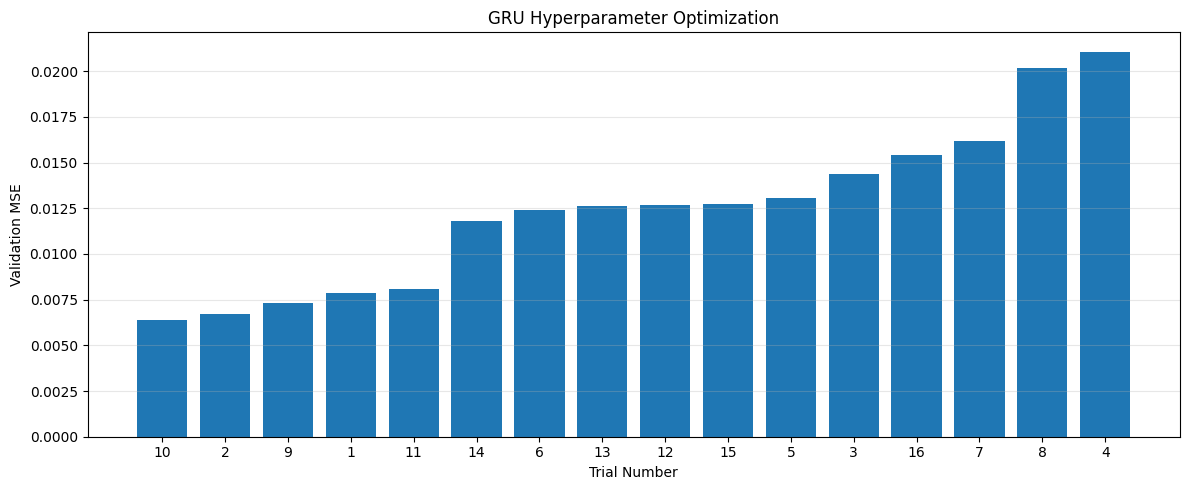

In [48]:
plt.figure(figsize=(12, 5))

plt.bar(
    results_df["trial"].astype(str),
    results_df["val_mse"]
)

plt.xlabel("Trial Number")
plt.ylabel("Validation MSE")
plt.title("GRU Hyperparameter Optimization")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Best Model Evaluation

In [49]:
best_model = tf.keras.models.load_model(
    "gru_checkpoints/best_gru.keras"
)

test_mse, test_mae = best_model.evaluate(
    X_test, y_test, verbose=0
)

print("Best hyperparameters:", best_config)
print("Test MSE:", test_mse)
print("Test MAE:", test_mae)
print("Parameter count:", best_model.count_params())

Best hyperparameters: {'units': 64, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32}
Test MSE: 0.024408401921391487
Test MAE: 0.08667847514152527
Parameter count: 14471


### Actual vs. Predicted Bike Counts

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


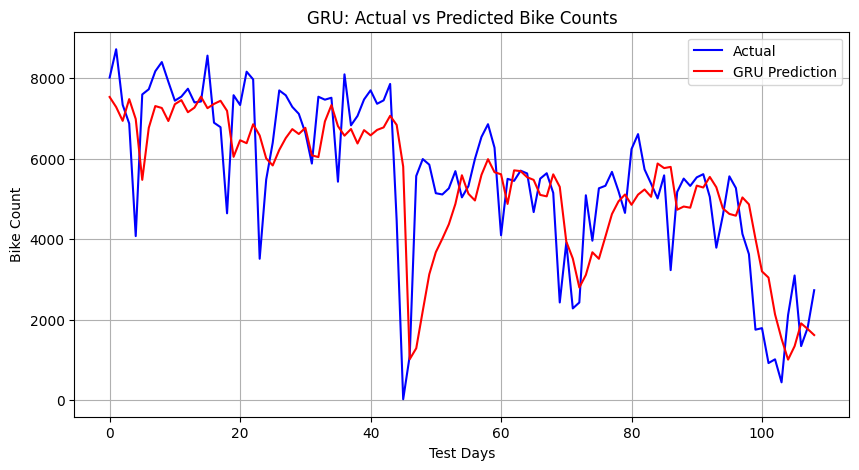

Bike Count MSE: 1938172.7933332303
Bike Count MAE: 1036.006990485235


In [51]:
predictions = best_model.predict(X_test)

pred_scaled = predictions[:, 0, 0].reshape(-1, 1)
actual_scaled = y_test[:, 0, 0].reshape(-1, 1)

pred_log = scalers["cnt"].inverse_transform(pred_scaled)
actual_log = scalers["cnt"].inverse_transform(actual_scaled)

pred_cnt = np.exp(pred_log).flatten()
actual_cnt = np.exp(actual_log).flatten()

plt.figure(figsize=(10, 5))

plt.plot(actual_cnt, label="Actual", color="blue")
plt.plot(pred_cnt, label="GRU Prediction", color="red")

plt.xlabel("Test Days")
plt.ylabel("Bike Count")
plt.title("GRU: Actual vs Predicted Bike Counts")

plt.legend()
plt.grid(True)
plt.show()

print("Bike Count MSE:", mean_squared_error(actual_cnt, pred_cnt))
print("Bike Count MAE:", mean_absolute_error(actual_cnt, pred_cnt))

### Conclusion

The GRU model was good at predicting bike counts, achieving a test MAE of 0.08668 and MSE of 0.02441. It performed better than the naive baseline (MAE = 0.098) and standard RNN (MAE = 0.09974). Grid search showed that the best model had 64 units, no dropout, a learning rate of 0.001, and a batch size of 32.